# Demo · type any query, see the guardrail decision
Edit `query` and re-run.  The 2-D plot shows the MFA component means (PCA) and where the query lands.

In [1]:
import sys, json, os
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
os.chdir(ROOT); sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd
from IPython.display import Image, display
pd.set_option('display.width', 200); pd.set_option('display.max_colwidth', 120)

In [2]:
from src.guardrail import MFAEVTGuardrail, FaissRetriever, GuardrailRetriever
from src.embeddings import embed
guard = MFAEVTGuardrail.load()
retriever = GuardrailRetriever(guardrail=guard, base_retriever=FaissRetriever.from_disk())
def check(query):
    docs = retriever.invoke(query); d = retriever.last_decision
    print(f'{query}\n  D2 = {d.d_sq:.1f}   S(q) = {d.p_value:.4f}   nearest component = {d.cluster}   '
          f'-> {d.label}  ({d.latency_ms:.2f} ms)')
    for doc in docs: print('   •', doc.metadata['chunk_id'], doc.page_content[:110].replace('\n',' '), '...')
    return d

In [3]:
for q in ['What is the FY2018 capital expenditure amount (in USD millions) for 3M?',
          'What are the main risk factors related to Tesla vehicle production?',
          'What was Microsoft revenue from its lunar data centers in 2019?',
          'Who painted the Mona Lisa?']:
    check(q); print()

C:\Users\Sai Krishna\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 3043.42it/s]

What is the FY2018 capital expenditure amount (in USD millions) for 3M?
  D2 = 446.2   S(q) = 1.0000   nearest component = 0   -> IN_DISTRIBUTION  (2.04 ms)
   • 3M_2022_10K_chunk_00373 At December 31, 2021, 3M had $4.8 billion of cash, cash equivalents and marketable securities, of which approx ...
   • 3M_2018_10K_chunk_00073 In 2018, 3M expended approximately $27 million for capital projects related to protecting the environment. Thi ...
   • 3M_2018_10K_chunk_00411 At December 31, 2018, 3M had $3.3 billion of cash, cash equivalents and marketable securities, of which approx ...

What are the main risk factors related to Tesla vehicle production?
  D2 = 433.3   S(q) = 1.0000   nearest component = 12   -> IN_DISTRIBUTION  (1.23 ms)
   • NVDA_10K_latest_chunk_00166 Risk Factors Summary Risks Related to Our Industry and Markets • Failure to meet the evolving needs of our ind ...
   • MICROSOFT_2016_10K_chunk_00166 ITEM 1A. RISK FACTORS Our operations and financial results are subject t

Who won the 2010 FIFA World Cup?
  D2 = 854.4   S(q) = 0.0003   nearest component = 12   -> OOD  (1.11 ms)


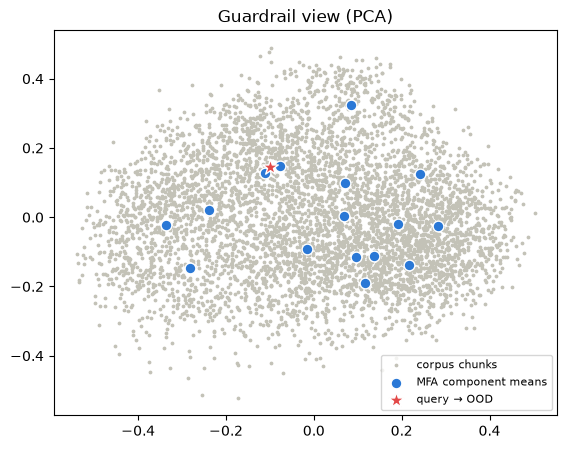

In [4]:
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
X = np.load('data/corpus_embeddings.npy')
pca = PCA(2, random_state=0).fit(X)
query = 'Who won the 2010 FIFA World Cup?'
d = check(query); q2 = pca.transform(embed(query))[0]
fig, ax = plt.subplots(figsize=(6.5,5))
ax.scatter(*pca.transform(X[::10]).T, s=3, c='#c3c2b7', label='corpus chunks')
mu = pca.transform(guard.mfa.means_)
ax.scatter(*mu.T, s=60, c='#2a78d6', edgecolor='white', label='MFA component means')
ax.scatter(*q2, s=140, marker='*', c='#e34948' if d.is_ood else '#1baf7a', edgecolor='white', label=f'query → {d.label}')
ax.legend(fontsize=8); ax.set_title('Guardrail view (PCA)'); plt.show()